In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
data = load_breast_cancer()
X = data.data
y = data.target

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [4]:
dt = DecisionTreeClassifier(random_state=42)

In [5]:
bagging = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),n_estimators=100,random_state=42)

In [6]:
models = {"Decision Tree": dt,"Bagging Classifier": bagging}

In [7]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("\n", name)
    print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(y_test, y_pred,average="weighted"), 4))
    print("Recall   :", round(recall_score(y_test, y_pred,average="weighted"), 4))
    print("F1-score :", round(f1_score(y_test, y_pred,average="weighted"), 4))



 Decision Tree
Accuracy : 0.9123
Precision: 0.9161
Recall   : 0.9123
F1-score : 0.913

 Bagging Classifier
Accuracy : 0.9386
Precision: 0.9384
Recall   : 0.9386
F1-score : 0.9384


In [8]:
from sklearn.ensemble import AdaBoostClassifier

In [9]:
base_model = DecisionTreeClassifier(max_depth=1, random_state=42)

In [10]:
model2 = AdaBoostClassifier(
    estimator=base_model,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

In [11]:
print("AdaBoost Classifier Performance")
print("Accuracy :", round(accuracy_score(y_test, y_pred),4))
print("Precision:", round(precision_score(y_test, y_pred),4))
print("Recall   :", round(recall_score(y_test, y_pred),4))
print("F1-score :", round(f1_score(y_test, y_pred),4))

AdaBoost Classifier Performance
Accuracy : 0.9386
Precision: 0.9452
Recall   : 0.9583
F1-score : 0.9517


In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

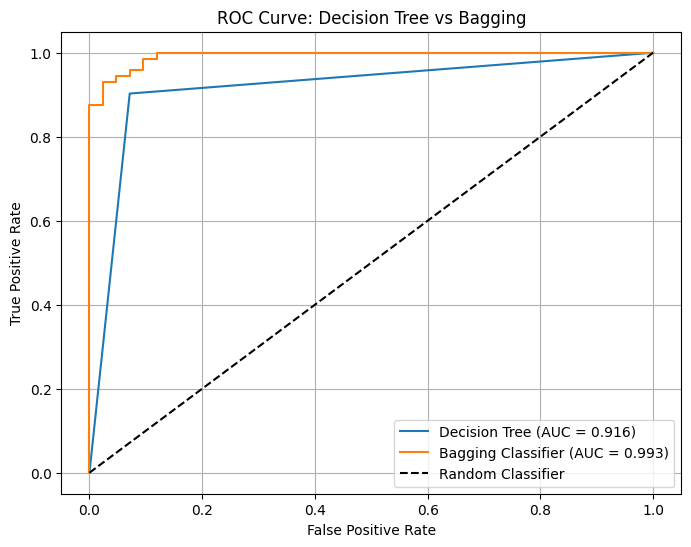

In [13]:

# Plot ROC curves for both models
plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

# Random classifier reference line
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Decision Tree vs Bagging")
plt.legend()
plt.grid(True)
plt.show()


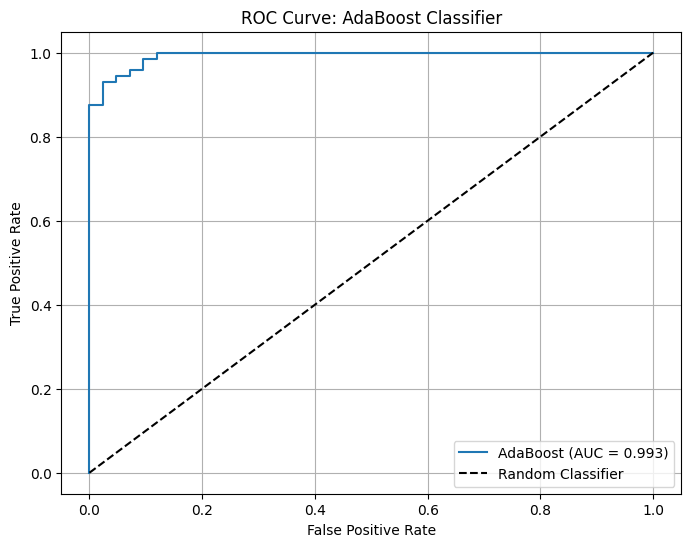

AUC Score: 0.9927


In [14]:

# Predict probabilities for the positive class
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AdaBoost (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: AdaBoost Classifier")
plt.legend()
plt.grid(True)
plt.show()

print("AUC Score:", round(auc, 4))
